In [1]:
# Step 1: Import libraries and load video

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

video_path = list(uploaded.keys())[0]

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Error: Video not found.")
else:
    print("Video loaded successfully.")

Saving 3987648-hd_1920_1080_24fps.mp4 to 3987648-hd_1920_1080_24fps.mp4
Video loaded successfully.


Number of detected feature points: 55


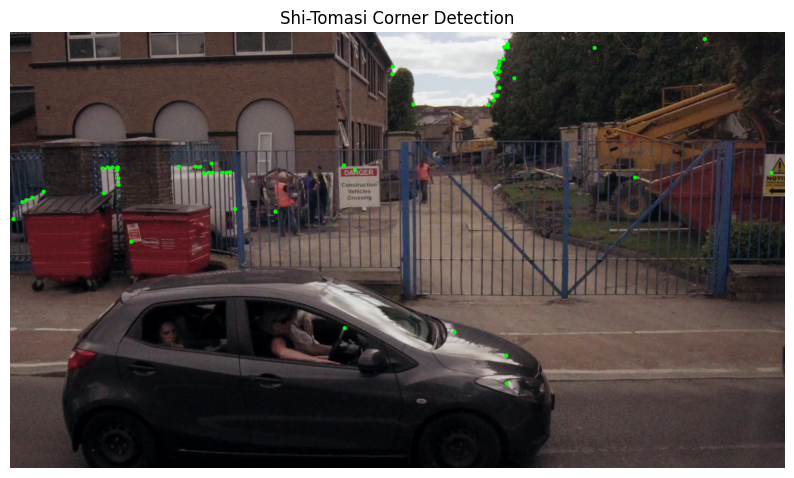

In [2]:
# Step 2: Detect feature points using Shi-Tomasi Corner Detection

ret, frame = cap.read()

if ret:
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    feature_params = dict(
        maxCorners=100,
        qualityLevel=0.3,
        minDistance=7,
        blockSize=7
    )

    points = cv2.goodFeaturesToTrack(
        gray,
        mask=None,
        **feature_params
    )

    print("Number of detected feature points:", len(points))

    result = frame.copy()

    for point in points:
        x, y = point.ravel()
        cv2.circle(result, (int(x), int(y)), 5, (0, 255, 0), -1)

    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title("Shi-Tomasi Corner Detection")
    plt.axis("off")
    plt.show()

In [3]:
# Step 3: Apply Lucas-Kanade Optical Flow

cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

ret, old_frame = cap.read()

old_gray = cv2.cvtColor(old_frame, cv2.COLOR_BGR2GRAY)

p0 = cv2.goodFeaturesToTrack(
    old_gray,
    mask=None,
    **feature_params
)

ret, new_frame = cap.read()

new_gray = cv2.cvtColor(new_frame, cv2.COLOR_BGR2GRAY)

p1, status, error = cv2.calcOpticalFlowPyrLK(
    old_gray,
    new_gray,
    p0,
    None
)

good_new = p1[status == 1]
good_old = p0[status == 1]

print("Tracked points:", len(good_new))

Tracked points: 55


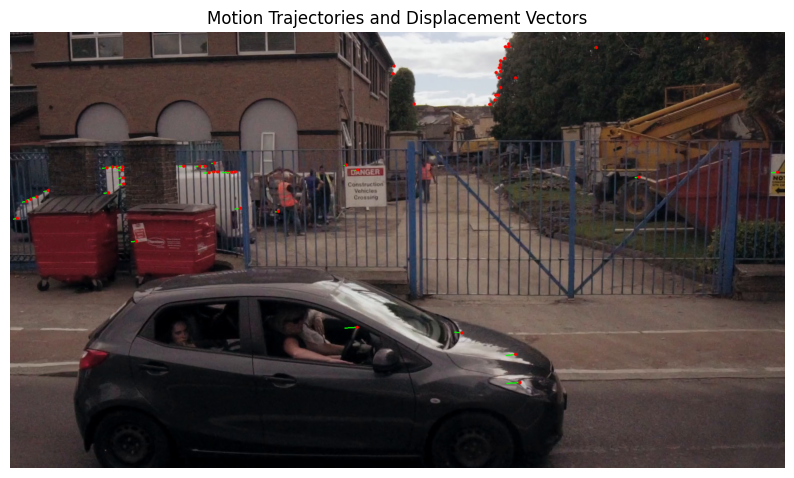

In [4]:
# Step 4: Draw motion trajectories and displacement vectors

trajectory_image = new_frame.copy()

for new, old in zip(good_new, good_old):
    x_new, y_new = new.ravel()
    x_old, y_old = old.ravel()

    cv2.arrowedLine(
        trajectory_image,
        (int(x_old), int(y_old)),
        (int(x_new), int(y_new)),
        (0, 255, 0),
        2
    )

    cv2.circle(
        trajectory_image,
        (int(x_new), int(y_new)),
        4,
        (0, 0, 255),
        -1
    )

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(trajectory_image, cv2.COLOR_BGR2RGB))
plt.title("Motion Trajectories and Displacement Vectors")
plt.axis("off")
plt.show()

In [5]:
# Step 5: Calculate motion direction and magnitude

displacements = []

for new, old in zip(good_new, good_old):
    x_new, y_new = new.ravel()
    x_old, y_old = old.ravel()

    dx = x_new - x_old
    dy = y_new - y_old

    magnitude = np.sqrt(dx**2 + dy**2)
    direction = np.degrees(np.arctan2(dy, dx))

    displacements.append(magnitude)

if len(displacements) > 0:
    average_displacement = np.mean(displacements)

    print("Average Displacement:", round(average_displacement, 2), "pixels")
    print("Average Motion Direction:", round(direction, 2), "degrees")
else:
    print("No motion points detected.")

Average Displacement: 9.73 pixels
Average Motion Direction: -6.03 degrees


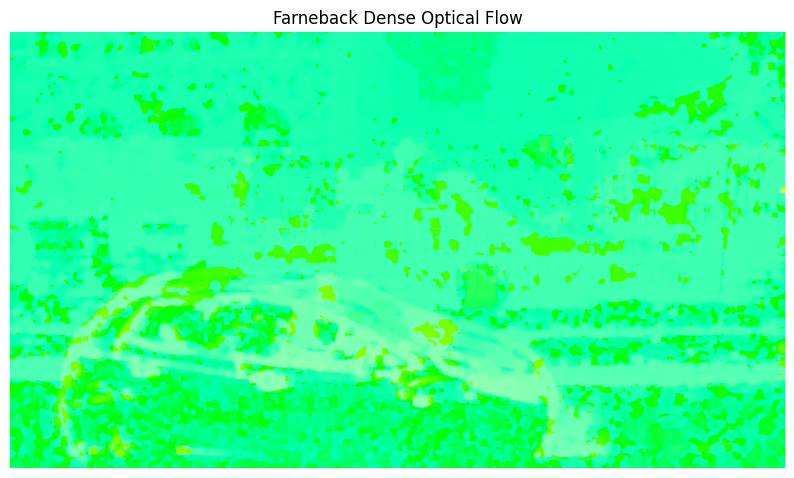

In [6]:
# Step 6: Apply Farneback Dense Optical Flow

cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

ret, frame1 = cap.read()
ret, frame2 = cap.read()

gray1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY)

flow = cv2.calcOpticalFlowFarneback(
    gray1,
    gray2,
    None,
    0.5,
    3,
    15,
    3,
    5,
    1.2,
    0
)

magnitude, angle = cv2.cartToPolar(
    flow[..., 0],
    flow[..., 1]
)

hsv = np.zeros_like(frame1)

hsv[..., 0] = angle * 180 / np.pi / 2
hsv[..., 1] = 255
hsv[..., 2] = cv2.normalize(
    magnitude,
    None,
    0,
    255,
    cv2.NORM_MINMAX
)

dense_flow = cv2.cvtColor(
    hsv,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(10, 6))
plt.imshow(dense_flow)
plt.title("Farneback Dense Optical Flow")
plt.axis("off")
plt.show()

In [7]:
# Step 7: Analyze factors affecting tracking accuracy

print("Effect of Object Speed:")
print("Higher object speed can increase displacement and tracking errors.")

print("\nEffect of Illumination:")
print("Sudden lighting changes can reduce feature tracking accuracy.")

print("\nEffect of Occlusion:")
print("When an object is hidden, some feature points may be lost.")

print("\nEffect of Camera Movement:")
print("Camera movement can create motion across many parts of the frame.")

Effect of Object Speed:
Higher object speed can increase displacement and tracking errors.

Effect of Illumination:
Sudden lighting changes can reduce feature tracking accuracy.

Effect of Occlusion:
When an object is hidden, some feature points may be lost.

Effect of Camera Movement:
Camera movement can create motion across many parts of the frame.


In [8]:
# Step 8: Calculate object displacement, trajectory and average speed

total_displacement = 0

for value in displacements:
    total_displacement += value

frame_rate = cap.get(cv2.CAP_PROP_FPS)

if frame_rate == 0:
    frame_rate = 30

time_between_frames = 1 / frame_rate

if len(displacements) > 0:
    average_displacement = np.mean(displacements)
    average_speed = average_displacement / time_between_frames

    print("Total Feature Displacement:", round(total_displacement, 2), "pixels")
    print("Average Displacement:", round(average_displacement, 2), "pixels")
    print("Average Speed:", round(average_speed, 2), "pixels/second")
else:
    print("Motion could not be calculated.")

Total Feature Displacement: 535.32 pixels
Average Displacement: 9.73 pixels
Average Speed: 233.59 pixels/second


In [9]:
# Step 9: Compare optical flow tracking with frame-by-frame detection

print("Optical Flow Tracking:")
print("- Tracks motion between consecutive frames.")
print("- Can provide displacement and trajectory information.")
print("- Useful when continuous movement needs to be monitored.")

print("\nFrame-by-Frame Object Detection:")
print("- Detects objects independently in each frame.")
print("- Usually requires an object detection model.")
print("- Can identify object classes such as person, car or animal.")

print("\nOptical flow is mainly focused on motion, while object detection")
print("is mainly focused on identifying and locating objects.")

Optical Flow Tracking:
- Tracks motion between consecutive frames.
- Can provide displacement and trajectory information.
- Useful when continuous movement needs to be monitored.

Frame-by-Frame Object Detection:
- Detects objects independently in each frame.
- Usually requires an object detection model.
- Can identify object classes such as person, car or animal.

Optical flow is mainly focused on motion, while object detection
is mainly focused on identifying and locating objects.


In [10]:
# Step 10: Summarize observations

print("Observations:")
print("1. Shi-Tomasi detects suitable feature points for tracking.")
print("2. Lucas-Kanade tracks selected feature points between frames.")
print("3. Motion trajectories show the path followed by tracked points.")
print("4. Motion magnitude and direction provide displacement information.")
print("5. Farneback provides dense motion information across the image.")
print("6. Object speed, illumination, occlusion and camera movement affect tracking.")
print("7. Optical flow is useful in surveillance, robotics, autonomous navigation,")
print("   object tracking and intelligent vision systems.")

cap.release()

Observations:
1. Shi-Tomasi detects suitable feature points for tracking.
2. Lucas-Kanade tracks selected feature points between frames.
3. Motion trajectories show the path followed by tracked points.
4. Motion magnitude and direction provide displacement information.
5. Farneback provides dense motion information across the image.
6. Object speed, illumination, occlusion and camera movement affect tracking.
7. Optical flow is useful in surveillance, robotics, autonomous navigation,
   object tracking and intelligent vision systems.
